In [59]:
# https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
import pandas as pd
import matplotlib.pyplot as plt

reviews_path = '/Users/colinwenzel/Desktop/CSE 3521 Project/group_sample_seed48.csv'

df = pd.read_csv(reviews_path)
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,515539,B001U8CED2,A38XS08I7CNOUY,nncym,3,4,1,1300060800,Nasty Stuff - Cats Hate It!,"I am owned by 5 cats and I foster another 17 cats for my local humane society, so I can give the reaction of 22 individual cats to this Kong Catnip Spray product. Most of these cats respond very positively to anything catnip - those who don't respond positively just don't respond to catnip much at all. I sprayed some of the Kong stuff on a couple of their favorite toys. I did notice a peculiar very unpleasant odor, but held the two toys out for the cats to sniff - they all took one sniff and bolted. This happened with all 22 of the cats, even those who don't normally have a reaction to catnip. I waited a couple of days just in case the scent was too strong, but got the same reaction. Really wish it did work as well as the reviews I read on the website......"
1,318059,B0024NKMEU,A1W1TQI2UZDY4R,Charles Baker,1,1,5,1269475200,Jerky spice,"This pack was exceptional for a ""newbie"" jerky maker like myself. I have to say all four flavors were good, but I preferred the original recipe. it tasted just like jerky you would buy for 5 times what it cost me to make it.<br />I do recommend adults with kids use the hot stuff. The kids ate all the other jerky but the spicy was too much for them so that's what I got to eat most of. All in all, this kit was excellent and the price was even better."
2,34626,B000GQTP1S,A1DRP529AHD8F1,"Ralph Kuser ""seeking intelligent life""",1,2,5,1302393600,Nice and hot!,These chips are just hot enough to make them interesting. The only other type of chip that came close was Habanero Dortitos which are hard to find.
3,131230,B00004RAMX,A275XT9A7OV1PL,wayfarer,0,0,1,1318550400,Junky gopher trap,This trap is very poor quality. Lock bar was too weak to engage or set trap. I threw it away because it was useless.
4,312766,B003KJ0DDC,A18QI1MZI0L8KB,"L. Arters ""living with MS""",0,0,5,1349827200,Delicious,"I love these whole wheat crackers by Lance! It's a nice big pack so I have plenty. I get cravings for these and they're great for a snack which I enjoy a pack for every day. Also great for an on the go snack when you go out, and for kids to snack on as well. And best of all, they're whole wheat!"


In [61]:
# Dataset Summary

number_of_reviews = len(df)
print("Number of reviews:", number_of_reviews)

# Count the words in each review
review_text = df["Text"].fillna("")
review_words = review_text.str.split()
word_counts = review_words.str.len()

average_length = word_counts.mean()
print("Average review length:", round(average_length, 2), "words")

# Count missing values in each column
print("Missing values:")
print(df.isna().sum())

# Count completely identical rows
identical_rows = df.duplicated().sum()
print("Identical rows:", identical_rows)

Number of reviews: 50000
Average review length: 79.93 words
Missing values:
Id                        0
ProductId                 0
UserId                    0
ProfileName               1
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   2
Text                      0
dtype: int64
Identical rows: 0


In [69]:
# Remove rows with a missing summary
clean_df = df.dropna(subset=["Summary"]).copy()

print("Rows after cleaning:", len(clean_df))

Rows after cleaning: 49998


In [77]:
# Dataset Summary

# Convert star ratings into three sentiment groups
sentiment_map = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

counts = clean_df["Sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"])

sentiment_table = counts.to_frame(name="Count")
sentiment_table["Percentage"] = (counts / len(clean_df) * 100)

display(sentiment_table)

,Count,Percentage
Sentiment,,
Negative,7202,14.404576
Neutral,3779,7.558302
Positive,39017,78.037121


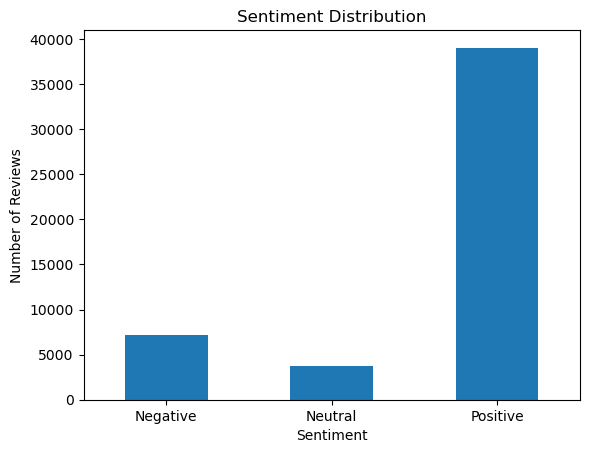

In [79]:
# Dataset Summary

counts.plot(kind="bar", rot=0)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()